# Load libraries

In [3]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

# Read the inputs.

In [4]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('SignalBG_ManyCouplings.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
print('Couplings shape = ',couplings_array.shape)

coupling_values = [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 1.0, 1.3, 1.5]
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


BG events =  1424245
Signal events =  3948813
Couplings shape =  (5373058,)
Coupling 0.0: 1424245 events
Coupling 0.1: 499919 events
Coupling 0.3: 499259 events
Coupling 0.5: 498028 events
Coupling 0.7: 496028 events
Coupling 0.8: 494946 events
Coupling 1.0: 491980 events
Coupling 1.3: 486434 events
Coupling 1.5: 482219 events


In [5]:
def compare_distributions(variable, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            data = variable[indices]
            plt.hist(data, bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=False)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        plt.show()

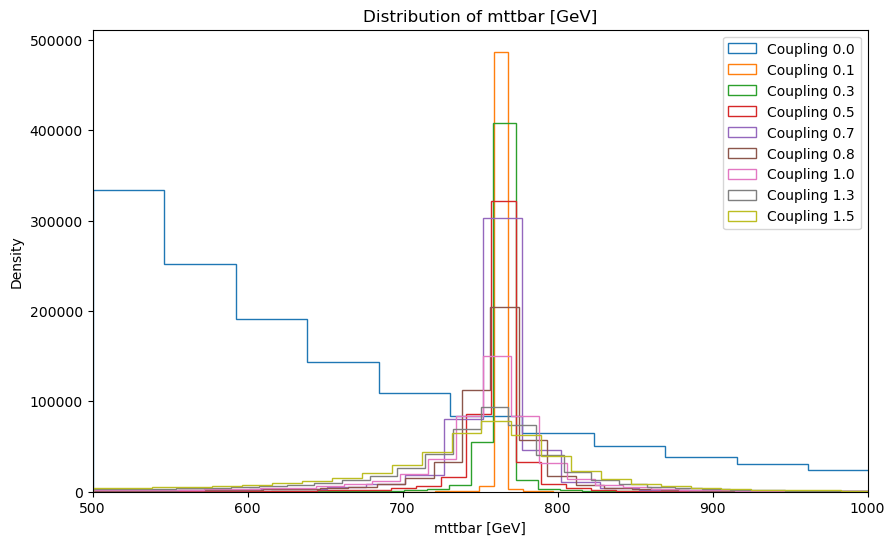

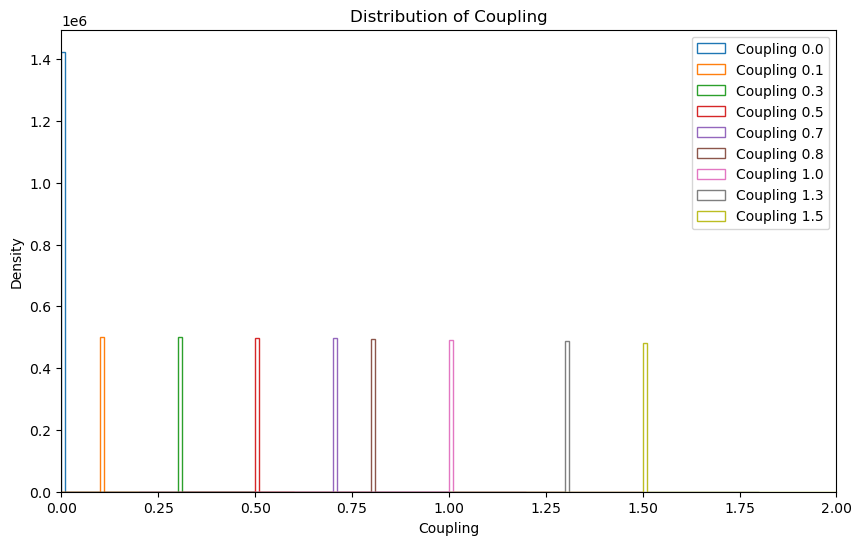

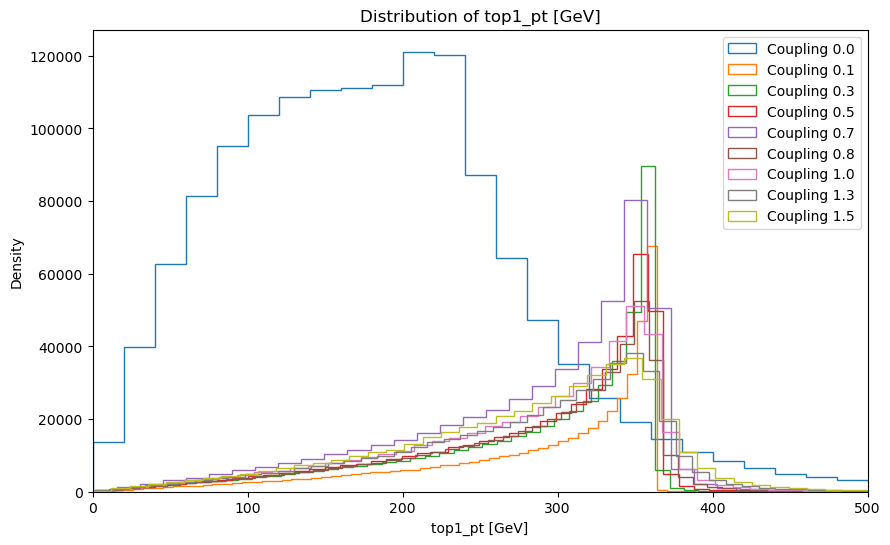

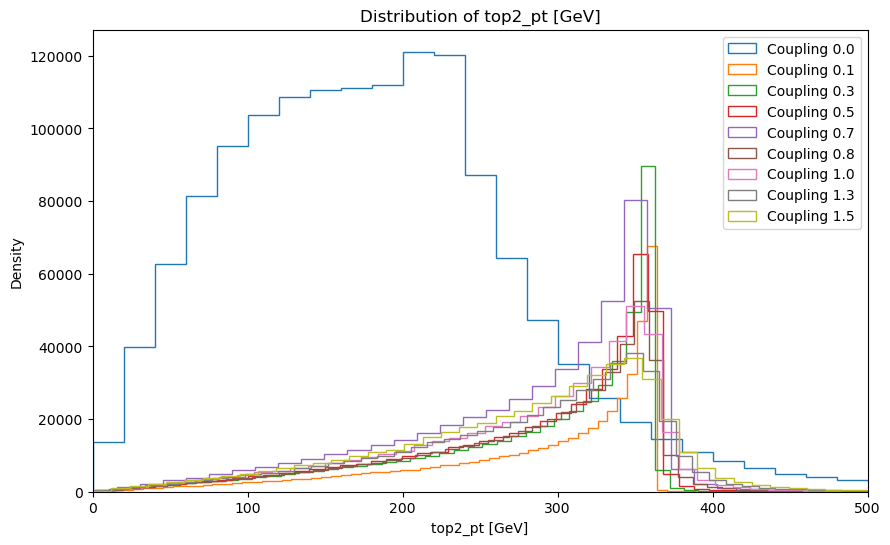

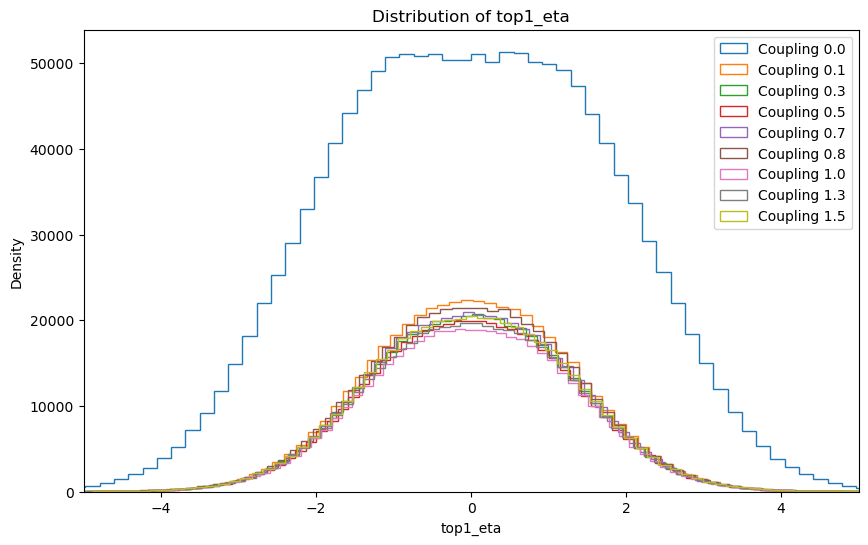

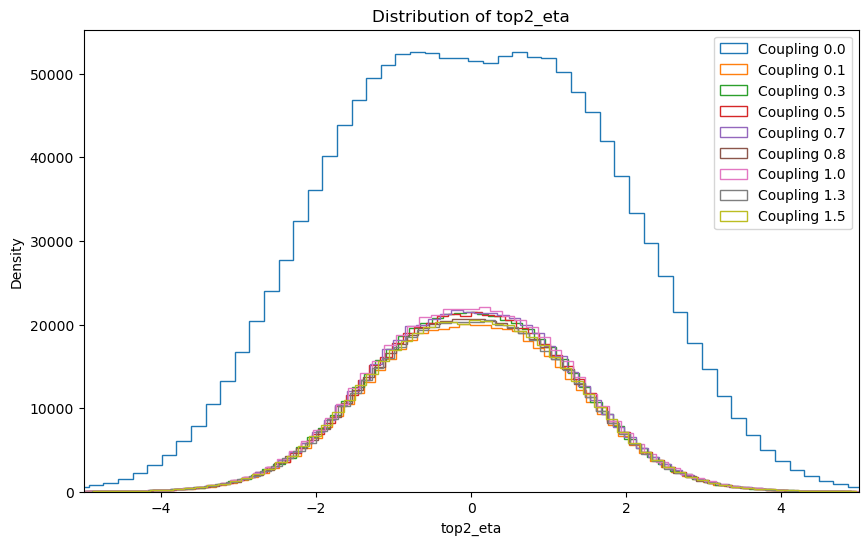

In [6]:
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], indices_per_coupling, x_range=[500,1000], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)

In [7]:
X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
X = rfn.structured_to_unstructured(X)
X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:]
X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
coupling_values_for_training = [ 0.1, 0.3, 0.5, 0.8, 1.0, 1.5]
X_couplings[background_indices] = np.random.choice(coupling_values_for_training, size=(len(background_indices),1))
y_category = np.empty_like(y)
for i in range(len(coupling_values)):
    coupling = coupling_values[i]
    indices = indices_per_coupling[coupling]
    y_category[indices] = i

y_category

# Form the data
X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1)], axis=1)
y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X shape =  (5373058, 8)
X example =  [ 2.2202632e+02 -7.1342796e-01  7.7109194e-01  2.2202632e+02
  6.8452752e-01 -2.3705008e+00  6.0781781e+02  3.0000001e-01]
y shape =  (5373058, 2)
y example =  [0. 0.]


In [8]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [9]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', LogScaler(), [6]),
    ('coupling', MinMaxScaler(), [7])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X)
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (5373058, 6)
X example after scaling =  [ 5.4028006   5.4028006  -0.49686924  0.47764915  6.409877    0.14285716]


# Separate the datasets for new observations

In [10]:
coupling_0p7_indices = np.argwhere(y[:,1]==4)
coupling_1p3_indices = np.argwhere(y[:,1]==7)

X_coupling_0p7 = X[coupling_0p7_indices]
X_coupling_1p3 = X[coupling_1p3_indices]
y_coupling_0p7 = y[coupling_0p7_indices]
y_coupling_1p3 = y[coupling_1p3_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_0p7_indices, coupling_1p3_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_0p7_indices, coupling_1p3_indices)), axis=0)

In [11]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (3512476, 6)
Validation set size =  (439060, 6)
Test set size =  (439060, 6)


In [12]:
import torch.nn as nn
# Define the Classifier
class Classifier(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(Classifier, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, X):
        logits = self.net(X)
        return logits

In [13]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [14]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor,
                              y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,
                              y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor,
                              y_test_tensor)

# Create DataLoader objects for training, validation, and testing in batches
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True, num_workers=8, persistent_workers=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=1024, shuffle=False, num_workers=8, persistent_workers=True, drop_last=True)
test_loader  = DataLoader(test_dataset, batch_size=1024, shuffle=False, num_workers=8)

In [44]:
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self, x_dim, hidden_dim=32, latent_dim=16):
        super(Encoder, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(x_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.LayerNorm(latent_dim),
        )
    def forward(self, X):
        latent = self.net(X)
        return latent
    

class ClassifierHead(nn.Module):
    def __init__(self, latent_dim=16, theta_dim=1, hidden_dim=64):
        super(ClassifierHead, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim + theta_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(),
            nn.Linear(hidden_dim, 1),
        )
    def forward(self, latent):
        logits = self.net(latent)
        return logits

class DecorrelatorHead(nn.Module):
    def __init__(self, latent_dim=16, hidden_dim=64, theta_dim=1):
        super(DecorrelatorHead, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, theta_dim),
        )
    def forward(self, latent):
        theta = self.net(latent)
        return theta

# --------------------------
# Gradient Reversal Layer
# --------------------------
class GradientReversalFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.lambd, None

def grad_reverse(x, lambd=1.0):
    return GradientReversalFunction.apply(x, lambd)

def reset_adversary(adversary, adv_optimizer, optimizer_kwargs=None, init_fn=None):
    # Reinitialize weights
    if init_fn is None:
        def init_fn(m):
            if hasattr(m, 'reset_parameters'):
                m.reset_parameters()
    adversary.apply(init_fn)
    
    # Recreate optimizer to clear momentum, Adam buffers, etc.
    new_adv_optimizer = type(adv_optimizer)(
        adversary.parameters(),
        **optimizer_kwargs
    )
    return new_adv_optimizer

In [45]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

encoder = Encoder(x_dim = X.shape[1]-1,)
classifier_head = ClassifierHead()
decorrelator_head = DecorrelatorHead()


criterion_classifier = nn.BCELoss(reduction='none')
criterion_adversarial = nn.MSELoss(reduction='none')
optimizer_classifier = optim.AdamW(list(encoder.parameters()) + list(classifier_head.parameters()), lr=0.0002, weight_decay=1e-3)
optimizer_adversarial = optim.AdamW(decorrelator_head.parameters(), lr=0.0002, weight_decay=1e-3)

scheduler_classifier = ReduceLROnPlateau(optimizer_classifier, "min", patience=5, factor=0.8)
scheduler_adversarial = ReduceLROnPlateau(optimizer_adversarial, "min", patience=5, factor=0.8)

def adv_lambda_scheduler(epoch, max_adv_lambda = 0.5, start_adv_lambda = 0.05, n_waming_up_epochs = 10):
    if epoch > n_waming_up_epochs:
        return max_adv_lambda
    else:
        adv_lambda = start_adv_lambda + epoch * (max_adv_lambda - start_adv_lambda) / n_waming_up_epochs
        return adv_lambda

In [46]:
# Get number of parameters of the model
#total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
#print("Total number of trainable parameters in the model:", total_params)

total_params_encoder = sum(p.numel() for p in encoder.parameters() if p.requires_grad)
total_params_classifier_head = sum(p.numel() for p in classifier_head.parameters() if p.requires_grad)
print("Total number of trainable parameters in the encoder:", total_params_encoder)
print("Total number of trainable parameters in the classifier head:", total_params_classifier_head)
print("Total = ", total_params_encoder + total_params_classifier_head)
print("Total number of trainable parameters in the decorrelator head:", sum(p.numel() for p in decorrelator_head.parameters() if p.requires_grad))

Total number of trainable parameters in the encoder: 816
Total number of trainable parameters in the classifier head: 5633
Total =  6449
Total number of trainable parameters in the decorrelator head: 5569


In [47]:
# Training loop on mini-batches with loss stored for plotting
train_losses_adversarial = []
train_losses_classifier = []
val_losses_adversarial = []
val_losses_classifier = []
R2_train = []
R2_val = []
num_epochs = 100
adv_weight = 0.5
        

encoder.to(device)
classifier_head.to(device)
decorrelator_head.to(device)

for epoch in range(num_epochs):
    # run over batches of data
    running_loss_adversarial = 0.0
    running_loss_classifier = 0.0
    running_R2 = 0.0

    adv_lambda = adv_lambda_scheduler(epoch)

    # Reset adversary condition
    if epoch % 8 == 0 and epoch != 0:
        optimizer_adversarial = reset_adversary(decorrelator_head, optimizer_adversarial, optimizer_kwargs={'lr':0.0002, 'weight_decay':0.001})
        print("Adversary reset.")
    
    for inputs, targets in train_loader:
        inputs_device = inputs.to(device)
        targets_device = targets[:,0].to(device)
        n_signal = torch.sum(targets_device==1).item()
        n_background = torch.sum(targets_device==0).item()
        weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))

        # Disable encoder gradients so adversary does not update encoder
        encoder.eval()
        with torch.no_grad():
            z_no_grad = encoder(inputs_device[:, :-1])

        decorrelator_head.train()
        optimizer_adversarial.zero_grad()

        decorrelator_output = decorrelator_head(z_no_grad)
        loss_adv_only = (weights * criterion_adversarial(decorrelator_output.squeeze(), inputs_device[:, -1])).mean()

        loss_adv_only.backward()
        optimizer_adversarial.step()

        ###############################
        # 2. MAIN STEP (update encoder + classifier)
        ###############################
        # IMPORTANT: DO NOT zero_grad on optimizer_adversarial again here

        encoder.train()
        optimizer_classifier.zero_grad()
        
        # normal forward with gradient enabled
        z = encoder(inputs_device[:, :-1])
        theta = inputs_device[:, -1].reshape(-1,1)

        classifier_output = classifier_head(torch.cat([z, theta], dim=1))
        classifier_output = torch.sigmoid(classifier_output)

        loss_classifier = (weights * criterion_classifier(classifier_output.squeeze(), targets_device)).mean()

        # adversarial loss via GRL (gradient into encoder reversed)
        z_rev = grad_reverse(z, lambd=adv_lambda)
        decorrelator_output = decorrelator_head(z_rev)
        loss_adv_for_encoder = (weights * criterion_adversarial(decorrelator_output.squeeze(), inputs_device[:, -1])).mean()

        loss = loss_classifier + adv_weight * loss_adv_for_encoder
        loss.backward()

        optimizer_classifier.step()
        
        running_loss_adversarial += loss_adv_only.item()
        running_loss_classifier += loss_classifier.item()

        # Calculate R2 for monitoring
        r2 = 1 - torch.sum((decorrelator_output.squeeze() - inputs_device[:, -1])**2) / torch.sum((inputs_device[:, -1] - torch.mean(inputs_device[:, -1]))**2)
        running_R2 += r2.item()

    # compute avergae loss over all batches
    train_losss_adversarial = running_loss_adversarial / len(train_loader)
    train_loss_classifier = running_loss_classifier / len(train_loader)
    train_losses_adversarial.append(train_losss_adversarial)
    train_losses_classifier.append(train_loss_classifier)
    r2_train = running_R2 / len(train_loader)
    R2_train.append(r2_train)



    # Validation step
    encoder.eval()
    classifier_head.eval()
    decorrelator_head.eval()
    val_loss_classifier = 0.0
    val_loss_adversarial = 0.0
    running_R2_val = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            z = encoder(inputs_device[:, :-1])
            theta = inputs_device[:, -1].reshape(inputs_device[:, -1].shape[0],1)
            classifier_output = classifier_head(torch.cat([z,theta],dim=1))
            classifier_output = torch.sigmoid(classifier_output)
            loss_classifier = criterion_classifier(classifier_output.squeeze(), targets_device)

            decorrelator_output = decorrelator_head(z)

            # Weight according to number of S/B events
            n_signal = torch.sum(targets_device==1).item()
            n_background = torch.sum(targets_device==0).item()
            weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))
            loss_classifier = (loss_classifier * weights).mean()

            loss_adversarial = criterion_adversarial(decorrelator_output.squeeze(), inputs_device[:, -1])
            loss_adversarial = (loss_adversarial * weights).mean()

            # Calculate R2 for monitoring
            r2 = 1 - torch.sum((decorrelator_output.squeeze() - inputs_device[:, -1])**2) / torch.sum((inputs_device[:, -1] - torch.mean(inputs_device[:, -1]))**2)
            running_R2_val += r2.item()
        
            val_loss_classifier += loss_classifier.item()
            val_loss_adversarial += loss_adversarial.item()

            

    val_loss_classifier /= len(val_loader)
    val_loss_adversarial /= len(val_loader)
    val_losses_classifier.append(val_loss_classifier)
    val_losses_adversarial.append(val_loss_adversarial)
    r2_val = running_R2_val / len(val_loader)
    R2_val.append(r2_val)

    scheduler_classifier.step(val_loss_classifier)
    scheduler_adversarial.step(val_loss_classifier)
    print(f"Learning rate: {scheduler_classifier.get_last_lr()[0]}  Lambda reversal = {adv_lambda}")
    print(f"Epoch {epoch+1}/{num_epochs} Losses -> Classifier: {train_loss_classifier:.4f}, Val: {val_loss_classifier:.4f}, Adversarial: {train_losss_adversarial:.4f}, Val: {val_loss_adversarial:.4f}, R2 Train: {r2_train:.4f}, R2 Val: {r2_val:.4f}")

Learning rate: 0.0002  Lambda reversal = 0.05
Epoch 1/100 Losses -> Classifier: 0.2278, Val: 0.1697, Adversarial: 0.0487, Val: 0.0481, R2 Train: -0.0092, R2 Val: 0.0039
Learning rate: 0.0002  Lambda reversal = 0.095
Epoch 2/100 Losses -> Classifier: 0.1295, Val: 0.1275, Adversarial: 0.0478, Val: 0.0471, R2 Train: 0.0123, R2 Val: 0.0360
Learning rate: 0.0002  Lambda reversal = 0.14
Epoch 3/100 Losses -> Classifier: 0.1217, Val: 0.1157, Adversarial: 0.0464, Val: 0.0451, R2 Train: 0.0603, R2 Val: 0.0972
Learning rate: 0.0002  Lambda reversal = 0.185
Epoch 4/100 Losses -> Classifier: 0.1201, Val: 0.1191, Adversarial: 0.0456, Val: 0.0457, R2 Train: 0.0840, R2 Val: 0.0820
Learning rate: 0.0002  Lambda reversal = 0.22999999999999998
Epoch 5/100 Losses -> Classifier: 0.1188, Val: 0.1156, Adversarial: 0.0453, Val: 0.0448, R2 Train: 0.0944, R2 Val: 0.1071
Learning rate: 0.0002  Lambda reversal = 0.275
Epoch 6/100 Losses -> Classifier: 0.1190, Val: 0.1140, Adversarial: 0.0452, Val: 0.0446, R2 Tra

In [48]:
save_model = True
if save_model:
    print("Saving model...")
    torch.save(encoder.state_dict(), 'encoder_pNN+Adv_ttbar.pth')
    torch.save(classifier_head.state_dict(), 'classifier_head_pNN+Adv_ttbar.pth')

Saving model...


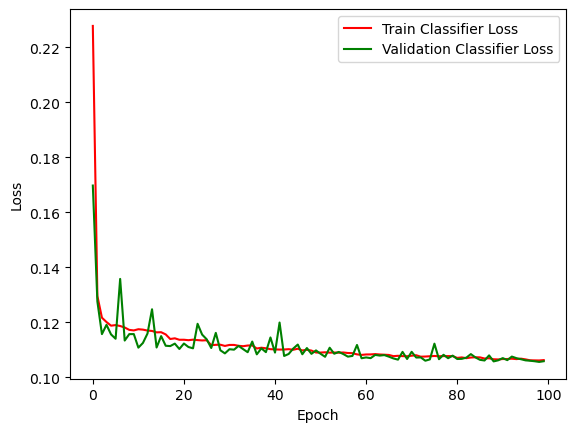

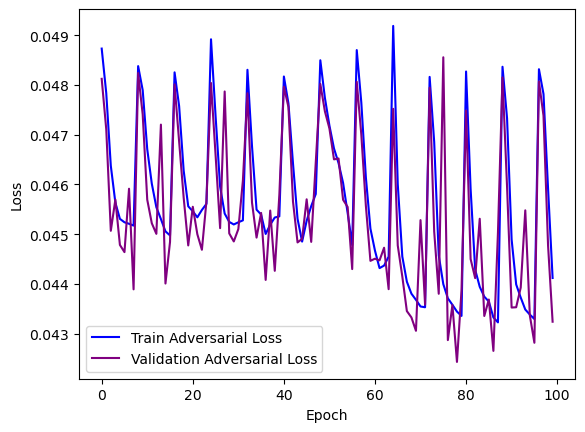

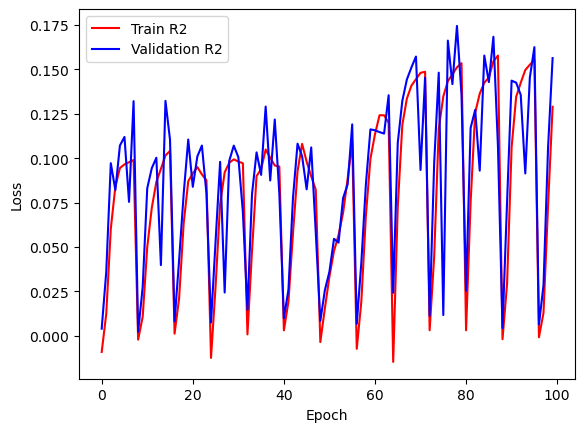

In [49]:
# Plot loss function for training and validation sets
plt.plot(train_losses_classifier, label='Train Classifier Loss', color='red')
#plt.plot(train_losses_adversarial, label='Train Adversarial Loss', color='blue')
plt.plot(val_losses_classifier, label='Validation Classifier Loss', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Classifier Loss', 'Validation Classifier Loss'])
#plt.yscale('log')
plt.show()

# Plot loss function for training and validation sets
plt.plot(train_losses_adversarial, label='Train Adversarial Loss', color='blue')
plt.plot(val_losses_adversarial, label='Validation Adversarial Loss', color='purple')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Adversarial Loss', 'Validation Adversarial Loss'])
#plt.yscale('log')
plt.show()


# Plot loss function for training and validation sets
plt.plot(R2_train, label='Train R2', color='red')
plt.plot(R2_val, label='Validation R2', color='blue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train R2', 'Validation R2'])
#plt.yscale('log')
plt.show()

NN: Using parametric model with theta dimension = 1


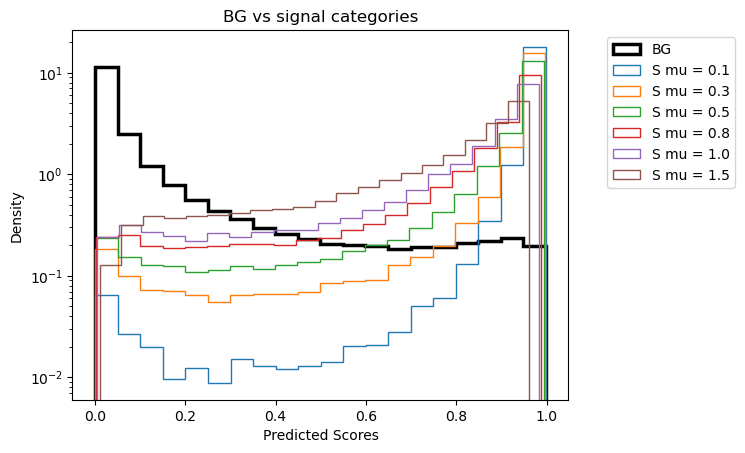

In [50]:
load_model = True
if load_model:
    eval_model = Classifier(x_dim = X.shape[1] - 1, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('pNN_ttbar.pth', weights_only=True))
    eval_encoder = Encoder(x_dim = X.shape[1]-1,)
    eval_encoder.load_state_dict(torch.load('encoder_pNN+Adv_ttbar.pth', weights_only=True))
    eval_classifier_head = ClassifierHead()
    eval_classifier_head.load_state_dict(torch.load('classifier_head_pNN+Adv_ttbar.pth', weights_only=True))
else:
    eval_encoder = encoder
    eval_classifier_head = classifier_head


eval_model.to('cpu')
eval_model.eval()

eval_encoder.to('cpu')
eval_encoder.eval()
eval_classifier_head.to('cpu')
eval_classifier_head.eval()

y_pred = eval_encoder(X_test_tensor[:,:-1])
theta_ref = X_test_tensor[:,-1].reshape(X_test_tensor.shape[0],1)
y_pred = torch.cat([y_pred, theta_ref], dim=1)
y_pred = eval_classifier_head(y_pred)
y_pred = torch.sigmoid(y_pred.detach())


# Filter the predicted events for true Signal and true Background
sb_label = y_test[:,0]
category_label = y_test[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = set(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

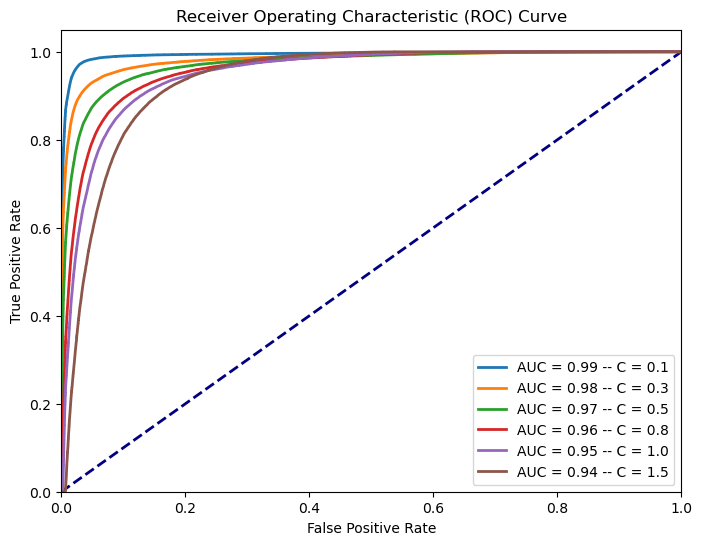

In [51]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

[[5.9176354  5.9176354  0.18074211 0.0758822  6.6642284  0.42857143]]


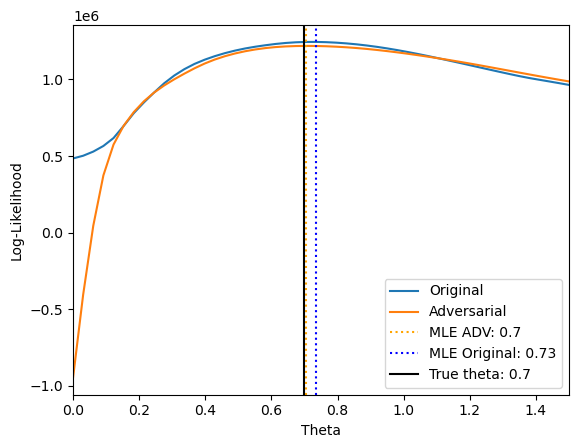

In [52]:
def ratio(x_obs, theta, model):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs, model):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio(X_obs, thetas, model)
    return torch.sum(torch.log(r_vals))


def ratio_adv(x_obs, theta, encoder, classifier_head):
    z = encoder(x_obs)
    X = torch.cat([z, theta], dim=1)
    logits = classifier_head(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood_adv(theta, X_obs, encoder, classifier_head):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio_adv(X_obs, thetas, encoder, classifier_head)
    return torch.sum(torch.log(r_vals))


new_data =  X_coupling_0p7
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-1] # Remove coupling column
X_obs = torch.tensor(new_data, requires_grad=False)


def plot_log_likelihoods(X_obs, true_theta, range, model, encoder, classifier_head):

    log_likelihoods = []
    log_likelihoods_adv = []
    x = np.linspace(range[0],range[1],50)
    for ix in x:
        theta_transformed = scaler["coupling"].transform([[ix]])[0,0]
        theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
        llh = log_likelihood(theta_tensor, X_obs, model)
        llh_adv = log_likelihood_adv(theta_tensor, X_obs, encoder, classifier_head)
        log_likelihoods.append(llh.item())
        log_likelihoods_adv.append(llh_adv.item())

    plt.plot(x, log_likelihoods, label="Original")
    plt.plot(x, log_likelihoods_adv, label="Adversarial")
    
    mle_adv = x[np.argmax(log_likelihoods_adv)]
    mle = x[np.argmax(log_likelihoods)]
    plt.axvline(mle_adv, color='orange', linestyle='dotted', label=f'MLE ADV: {round(mle_adv,2)}')
    plt.axvline(mle, color='blue', linestyle='dotted', label=f'MLE Original: {round(mle,2)}')
    plt.axvline(true_theta, color='black', linestyle='solid', label=f'True theta: {round(true_theta,2)}')
    

    
    plt.xlabel("Theta")
    plt.ylabel("Log-Likelihood")
    plt.xlim((min(x),max(x)))
    plt.legend()
    plt.show()

plot_log_likelihoods(X_obs, 0.7, [0.0,1.5], eval_model, eval_encoder, eval_classifier_head)

[[ 5.1701965   5.1701965  -0.64605135  1.155478    6.6021485   0.8571428 ]]


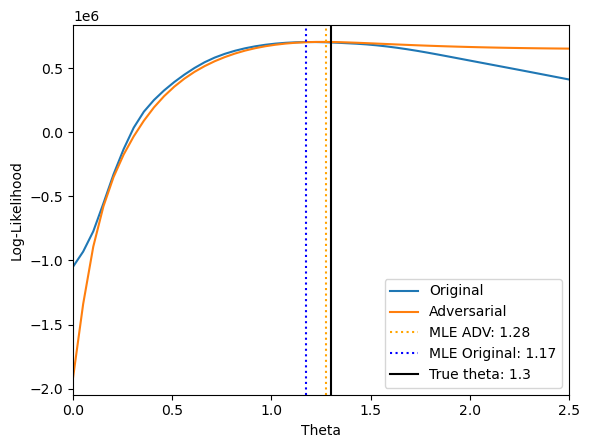

In [53]:
new_data =  X_coupling_1p3
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-1] # Remove coupling column
X_obs = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(X_obs, 1.3, [0.0,2.5], eval_model, eval_encoder, eval_classifier_head)

[5.883147  5.883147  1.1726326 1.1768066 6.63064  ]


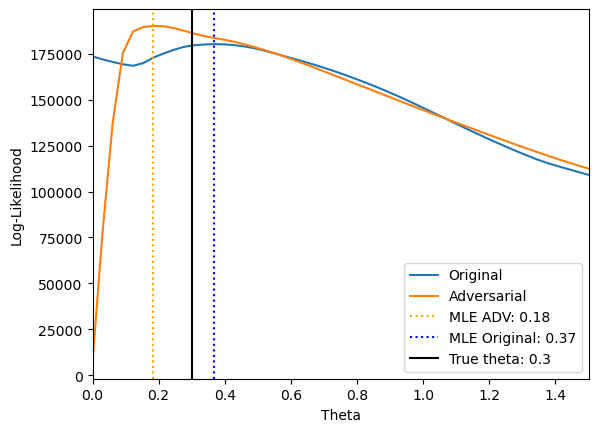

In [54]:
new_data =  X_test[:,:-1][y_test[:,1]==2] # [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 1.0, 1.3, 1.5]
print(new_data[0])
new_X = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(new_X, 0.3,[0.0,1.5], eval_model, eval_encoder, eval_classifier_head)

[ 5.6924486   5.6924486  -0.08204143  0.79863197  6.6340895 ]


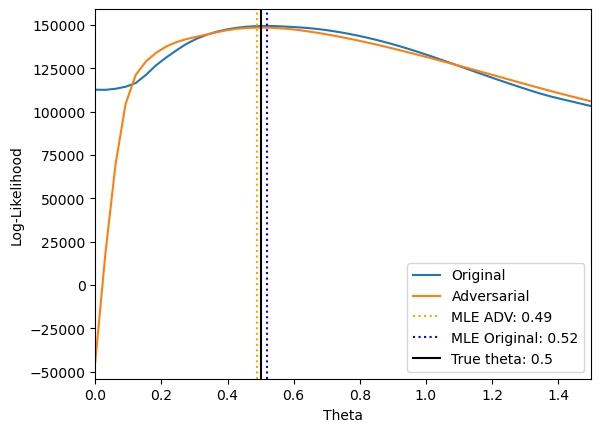

In [55]:
new_data =  X_test[:,:-1][y_test[:,1]==3] # [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 1.0, 1.3, 1.5]
print(new_data[0])
new_X = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(new_X, 0.5, [0.0,1.5], eval_model, eval_encoder, eval_classifier_head)

[5.9492054  5.9492054  0.69222826 0.37942153 6.7145953 ]


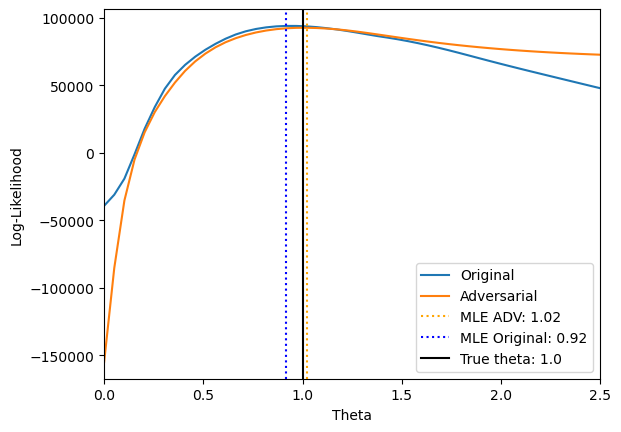

In [56]:
new_data =  X_test[:,:-1][y_test[:,1]==6] # [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 1.0, 1.3, 1.5]
print(new_data[0])
new_X = torch.tensor(new_data, requires_grad=False)


plot_log_likelihoods(new_X, 1.0, [0.0,2.5], eval_model, eval_encoder, eval_classifier_head)

[ 4.7931433   4.7931433   1.5769981  -0.98785514  6.7154865 ]


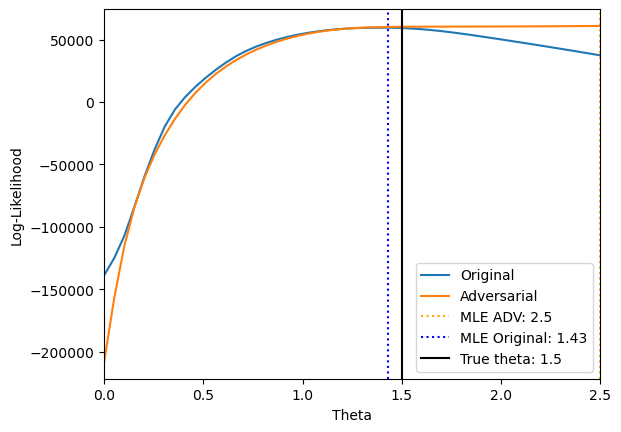

In [57]:
new_data =  X_test[:,:-1][y_test[:,1]==8] # [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 1.0, 1.3, 1.5]
print(new_data[0])
new_X = torch.tensor(new_data, requires_grad=False)


plot_log_likelihoods(new_X, 1.5, [0.0,2.5], eval_model, eval_encoder, eval_classifier_head)